In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from imblearn.over_sampling import SMOTE 

import warnings
warnings.filterwarnings('ignore')

In [95]:
df = pd.read_csv('/kaggle/input/datasets/walidnishat/dataseetclean/Games_Dataset_Clean.csv')

In [96]:
df['tags_list'] = df['tags'].apply(lambda x: [tag.strip() for tag in x.split(',')])

from sklearn.preprocessing import MultiLabelBinarizer
mlb = MultiLabelBinarizer()

tags_encoded = mlb.fit_transform(df['tags_list'])
tags_df = pd.DataFrame(tags_encoded, columns=mlb.classes_, index=df.index)

df = pd.concat([df, tags_df], axis=1)

df = df.drop(columns=['tags'])

In [97]:
top_tags = df[mlb.classes_].sum().sort_values(ascending=False).head(30).index
tag_columns = list(top_tags)

In [98]:
df['high_discount'] = (df['discount %'] > 50).astype(int)

features = ['metascore', 'review count', 'release year', 'original price']+tag_columns
X = df[features]
y = df['high_discount']

print(f"Target Distribution:\n{y.value_counts(normalize=True)}")

Target Distribution:
high_discount
0    0.741315
1    0.258685
Name: proportion, dtype: float64


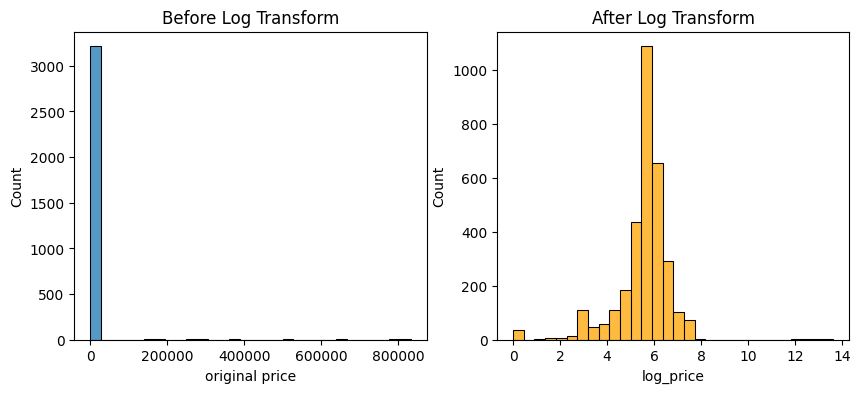

In [99]:
X['log_price'] = np.log1p(X['original price'])
X['log_reviews'] = np.log1p(X['review count'])


X = X.drop(columns=['original price', 'review count'])

# Visualization 
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['original price'], bins=30).set_title("Before Log Transform")
plt.subplot(1, 2, 2)
sns.histplot(X['log_price'], bins=30, color='orange').set_title("After Log Transform")
plt.show()

In [100]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

scaler = StandardScaler()
X_train_res = scaler.fit_transform(X_train_res)
X_test = scaler.transform(X_test)

print(f"Resampled Training Set Size: {len(X_train_res)}")

Resampled Training Set Size: 3824


In [101]:
log_model = LogisticRegression()
log_model.fit(X_train_res, y_train_res)
y_pred_log = log_model.predict(X_test)

tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_model.fit(X_train_res, y_train_res)
y_pred_tree = tree_model.predict(X_test)

print("--- Logistic Regression Report ---")
print(classification_report(y_test, y_pred_log))

print("\n--- Decision Tree Report ---")
print(classification_report(y_test, y_pred_tree))

--- Logistic Regression Report ---
              precision    recall  f1-score   support

           0       0.78      0.64      0.70       478
           1       0.31      0.47      0.38       167

    accuracy                           0.60       645
   macro avg       0.55      0.56      0.54       645
weighted avg       0.66      0.60      0.62       645


--- Decision Tree Report ---
              precision    recall  f1-score   support

           0       0.90      0.64      0.75       478
           1       0.43      0.78      0.56       167

    accuracy                           0.68       645
   macro avg       0.66      0.71      0.65       645
weighted avg       0.78      0.68      0.70       645



In [102]:
print(len(X.columns))
print(len(tree_model.feature_importances_))

34
34


In [103]:
import pandas as pd

importances = tree_model.feature_importances_

feat_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(feat_importance.head(20))

                    feature  importance
1              release year    0.417408
0                 metascore    0.378527
32                log_price    0.096218
33              log_reviews    0.031291
11             Multi-player    0.029522
15                 Strategy    0.015728
24       Steam Leaderboards    0.015429
27      Shared/Split Screen    0.005348
16                    Co-op    0.004978
12                      RPG    0.002138
14               Simulation    0.002138
5               Steam Cloud    0.000887
28    Remote Play on Tablet    0.000388
7   Full controller support    0.000000
9                    Action    0.000000
8                 Adventure    0.000000
3            Family Sharing    0.000000
2             Single-player    0.000000
17   Custom Volume Controls    0.000000
13                   Casual    0.000000
